In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q kagglehub

from google.colab import userdata
import os

os.environ["KAGGLE_API_KEY"] = userdata.get("KAGGLE_API_KEY")

In [3]:
import kagglehub

path = kagglehub.dataset_download(
    "samuelayman/stairs",
    output_dir="/content/drive/MyDrive/Hazard_Detection/raw_datasets/stairs/kaggle_1"
)

print(path)

100%|██████████| 102M/102M [00:00<00:00, 115MB/s] 

Extracting files...


/content/drive/MyDrive/Hazard_Detection/raw_datasets/stairs/kaggle_1


In [4]:
for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)

    if level > 3:
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:5]:
        print("  " * (level + 1) + file)

kaggle_1/
  final stairs/
    0002.jpg
    0003.jpg
    0005.jpg
    0006.jpg
    0007.jpg
    labels/
      0002.txt
      0003.txt
      0005.txt
      0006.txt
      0007.txt
  .complete/
    datasets/
      samuelayman/


In [7]:
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/stairs/kaggle_1/final stairs"
)

label_files = list((BASE_DIR / "labels").glob("*.txt"))

print("Number of labels:", len(label_files))

for file in label_files[:5]:
    print(f"\n{file.name}")
    print(file.read_text()[:500])

Number of labels: 959

0002.txt
0 0.466641 0.578535 0.680937 0.811094


0003.txt
0 0.500781 0.666631 0.403125 0.619043


0005.txt
0 0.493613 0.553145 0.747617 0.830156


0006.txt
0 0.425361 0.772979 0.522207 0.393652


0007.txt
0 0.488848 0.683291 0.725391 0.223809



In [8]:
from pathlib import Path
import random
import shutil
import yaml

# -----------------------------
# PATHS
# -----------------------------

BASE_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/stairs/kaggle_1/final stairs"
)

IMAGE_DIR = BASE_DIR
LABEL_DIR = BASE_DIR / "labels"
OUTPUT_DIR = BASE_DIR / "YOLO"

# -----------------------------
# SETTINGS
# -----------------------------

RANDOM_SEED = 42

# Source class 0 (stairs) -> master class 10 (temporary stairs_up)
CLASS_MAPPING = {
    0: 10
}

MASTER_CLASSES = [
    "person",
    "two_wheeler",
    "car",
    "auto_rickshaw",
    "large_vehicle",
    "large_animal",
    "dog",
    "pothole",
    "open_drain",
    "speed_breaker",
    "stairs_up",
    "stairs_down",
    "curb_or_step",
    "obstacle",
    "vendor_stall",
    "bench",
    "chair",
    "door",
    "sports_balls",
    "traffic_lights",
    "other_hazards"
]

# -----------------------------
# CHECK SOURCE
# -----------------------------

if not IMAGE_DIR.exists():
    raise FileNotFoundError(f"Image directory not found: {IMAGE_DIR}")

if not LABEL_DIR.exists():
    raise FileNotFoundError(f"Label directory not found: {LABEL_DIR}")

if OUTPUT_DIR.exists():
    raise FileExistsError(
        f"Output already exists: {OUTPUT_DIR}\n"
        "Rename or remove it only after checking its contents."
    )

label_files = sorted(LABEL_DIR.glob("*.txt"))

image_extensions = [".jpg", ".jpeg", ".png", ".webp"]

pairs = []

for label_file in label_files:
    image_file = None

    for ext in image_extensions:
        candidate = IMAGE_DIR / (label_file.stem + ext)
        if candidate.exists():
            image_file = candidate
            break

    if image_file:
        pairs.append((image_file, label_file))

print("Label files:", len(label_files))
print("Matched image-label pairs:", len(pairs))
print("Unmatched labels:", len(label_files) - len(pairs))

# -----------------------------
# CHECK AND REMAP LABELS
# -----------------------------

for image_file, label_file in pairs:

    lines = label_file.read_text().splitlines()

    for line in lines:
        if not line.strip():
            continue

        values = line.split()

        if len(values) != 5:
            raise ValueError(
                f"Unexpected annotation format in {label_file.name}: {line}"
            )

        source_id = int(float(values[0]))

        if source_id not in CLASS_MAPPING:
            raise ValueError(
                f"Unexpected class ID {source_id} in {label_file.name}"
            )

# -----------------------------
# SHUFFLE AND SPLIT
# -----------------------------

random.seed(RANDOM_SEED)
random.shuffle(pairs)

total = len(pairs)

train_end = int(total * 0.8)
valid_end = int(total * 0.9)

splits = {
    "train": pairs[:train_end],
    "valid": pairs[train_end:valid_end],
    "test": pairs[valid_end:]
}

# -----------------------------
# CREATE OUTPUT FOLDERS
# -----------------------------

for split in splits:
    (OUTPUT_DIR / "images" / split).mkdir(parents=True)
    (OUTPUT_DIR / "labels" / split).mkdir(parents=True)

# -----------------------------
# COPY IMAGES AND REMAP LABELS
# -----------------------------

for split, split_pairs in splits.items():

    for image_file, label_file in split_pairs:

        shutil.copy2(
            image_file,
            OUTPUT_DIR / "images" / split / image_file.name
        )

        remapped_lines = []

        for line in label_file.read_text().splitlines():

            if not line.strip():
                continue

            values = line.split()
            old_id = int(float(values[0]))

            values[0] = str(CLASS_MAPPING[old_id])

            remapped_lines.append(" ".join(values))

        output_label = OUTPUT_DIR / "labels" / split / label_file.name

        output_label.write_text(
            "\n".join(remapped_lines) + "\n"
        )

# -----------------------------
# CREATE DATA.YAML
# -----------------------------

data_yaml = {
    "path": str(OUTPUT_DIR),
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "nc": len(MASTER_CLASSES),
    "names": MASTER_CLASSES
}

with open(OUTPUT_DIR / "data.yaml", "w") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)

# -----------------------------
# SUMMARY
# -----------------------------

print("\nCONVERSION COMPLETE")
print("-------------------")

for split, split_pairs in splits.items():
    print(f"{split}: {len(split_pairs)} images")

print("\nOutput:", OUTPUT_DIR)
print("Source class 0 remapped to master class 10.")
print("Original dataset has not been modified.")

Label files: 959
Matched image-label pairs: 959
Unmatched labels: 0

CONVERSION COMPLETE
-------------------
train: 767 images
valid: 96 images
test: 96 images

Output: /content/drive/MyDrive/Hazard_Detection/raw_datasets/stairs/kaggle_1/final stairs/YOLO
Source class 0 remapped to master class 10.
Original dataset has not been modified.


In [9]:
!pip install -q ultralytics matplotlib pyyaml pandas

Total annotations: 995
Total classes: 1


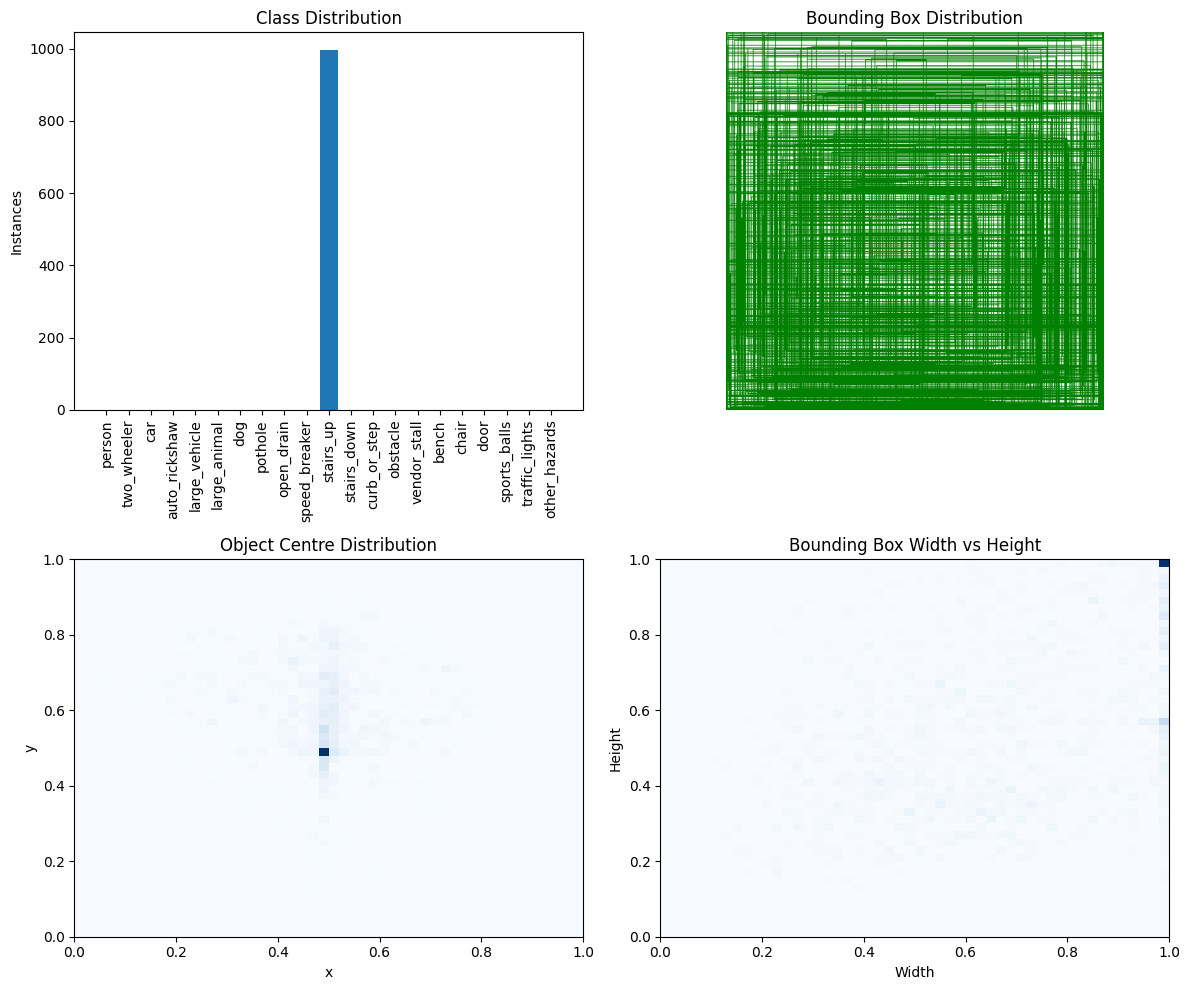

Saved analysis to: /content/drive/MyDrive/Hazard_Detection/raw_datasets/stairs/kaggle_1/final stairs/YOLO/dataset_analysis.jpg


In [10]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import ImageDraw, Image

# Dataset location
DATASET_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/stairs/kaggle_1/final stairs/YOLO")

# Read data.yaml
yaml_path = DATASET_DIR / "data.yaml"

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

names = config["names"]

if isinstance(names, list):
    names = dict(enumerate(names))

# Find label directories using the dataset splits
base = Path(config.get("path", DATASET_DIR))

if not base.is_absolute():
    base = (yaml_path.parent / base).resolve()

label_dirs = set()

for split in ["train", "val", "valid", "test"]:
    split_path = config.get(split)

    if not split_path:
        continue

    paths = split_path if isinstance(split_path, list) else [split_path]

    for p in paths:
        p = Path(p)

        if not p.is_absolute():
            p = (base / p).resolve()

        parts = list(p.parts)

        if "images" in parts:
            parts[parts.index("images")] = "labels"
            label_dirs.add(Path(*parts))
        else:
            print("Check label folder for:", p)

# Read annotations
classes = []
boxes = []

for label_dir in label_dirs:
    if not label_dir.exists():
        print("Missing:", label_dir)
        continue

    for file in label_dir.rglob("*.txt"):
        with open(file, "r") as f:
            for line in f:
                values = line.strip().split()

                if len(values) < 5:
                    continue

                cls, x, y, w, h = map(float, values[:5])

                classes.append(int(cls))
                boxes.append([x, y, w, h])

classes = np.array(classes)
boxes = np.array(boxes)

print("Total annotations:", len(classes))
print("Total classes:", len(set(classes)))

# Class distribution
counts = np.bincount(
    classes.astype(int),
    minlength=len(names)
)

# Generate plots
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

# 1. Class distribution
ax[0, 0].bar(range(len(names)), counts)

ax[0, 0].set_xticks(range(len(names)))
ax[0, 0].set_xticklabels(
    [names[i] for i in range(len(names))],
    rotation=90
)

ax[0, 0].set_ylabel("Instances")
ax[0, 0].set_title("Class Distribution")

# 2. Bounding box visualization
img = Image.new("RGB", (1000, 1000), "white")
draw = ImageDraw.Draw(img)

for x, y, w, h in boxes[:500]:
    x1 = (x - w/2) * 1000
    y1 = (y - h/2) * 1000
    x2 = (x + w/2) * 1000
    y2 = (y + h/2) * 1000

    draw.rectangle([x1, y1, x2, y2], outline="green", width=2)

ax[0, 1].imshow(img)
ax[0, 1].set_title("Bounding Box Distribution")
ax[0, 1].axis("off")

# 3. Object centre distribution
ax[1, 0].hist2d(
    boxes[:, 0],
    boxes[:, 1],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 0].set_xlabel("x")
ax[1, 0].set_ylabel("y")
ax[1, 0].set_title("Object Centre Distribution")

# 4. Width-height distribution
ax[1, 1].hist2d(
    boxes[:, 2],
    boxes[:, 3],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 1].set_xlabel("Width")
ax[1, 1].set_ylabel("Height")
ax[1, 1].set_title("Bounding Box Width vs Height")

plt.tight_layout()

# Save results
output_path = DATASET_DIR / "dataset_analysis.jpg"

plt.savefig(output_path, dpi=200)
plt.show()

print("Saved analysis to:", output_path)

In [13]:
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/stairs/kaggle_1/final stairs"
)

paths = {
    "Original labels": BASE / "labels",
    "Converted YOLO labels": BASE / "YOLO" / "labels"
}

for name, path in paths.items():
    print(f"\n{name}")
    print("Path exists:", path.exists())

    if path.exists():
        files = list(path.rglob("*.txt"))
        print("Number of TXT files:", len(files))

        if files:
            print("Sample file:", files[0])
            print("Sample contents:")
            print(files[0].read_text()[:300])


Original labels
Path exists: True
Number of TXT files: 959
Sample file: /content/drive/MyDrive/Hazard_Detection/raw_datasets/stairs/kaggle_1/final stairs/labels/0002.txt
Sample contents:
0 0.466641 0.578535 0.680937 0.811094


Converted YOLO labels
Path exists: True
Number of TXT files: 959
Sample file: /content/drive/MyDrive/Hazard_Detection/raw_datasets/stairs/kaggle_1/final stairs/YOLO/labels/train/240_F_112464962_3SEO6A8wQiPlyHZ3UyEOfIy5JmxMY3AS.txt
Sample contents:
10 0.503594 0.644771 0.628188 0.324792



In [14]:
from pathlib import Path
from collections import Counter

LABEL_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/stairs/kaggle_1/final stairs/YOLO/labels"
)

MASTER_CLASSES = {
    0: "person",
    1: "two_wheeler",
    2: "car",
    3: "auto_rickshaw",
    4: "large_vehicle",
    5: "large_animal",
    6: "dog",
    7: "pothole",
    8: "open_drain",
    9: "speed_breaker",
    10: "stairs_up",
    11: "stairs_down",
    12: "curb_or_step",
    13: "obstacle",
    14: "vendor_stall",
    15: "bench",
    16: "chair",
    17: "door",
    18: "sports_balls",
    19: "traffic_lights",
    20: "other_hazards"
}

counts = Counter()

for label_file in LABEL_DIR.rglob("*.txt"):
    with open(label_file) as f:
        for line in f:
            if line.strip():
                class_id = int(line.split()[0])
                counts[class_id] += 1

print("CLASS DISTRIBUTION\n")

for class_id, name in MASTER_CLASSES.items():
    print(f"{class_id:2} | {name:18} | {counts[class_id]}")

print("\nTotal bounding boxes:", sum(counts.values()))

CLASS DISTRIBUTION

 0 | person             | 0
 1 | two_wheeler        | 0
 2 | car                | 0
 3 | auto_rickshaw      | 0
 4 | large_vehicle      | 0
 5 | large_animal       | 0
 6 | dog                | 0
 7 | pothole            | 0
 8 | open_drain         | 0
 9 | speed_breaker      | 0
10 | stairs_up          | 995
11 | stairs_down        | 0
12 | curb_or_step       | 0
13 | obstacle           | 0
14 | vendor_stall       | 0
15 | bench              | 0
16 | chair              | 0
17 | door               | 0
18 | sports_balls       | 0
19 | traffic_lights     | 0
20 | other_hazards      | 0

Total bounding boxes: 995


In [15]:
from pathlib import Path
import numpy as np

LABELS = Path("/content/drive/MyDrive/Hazard_Detection/raw_datasets/stairs/kaggle_1/final stairs/YOLO/labels")   # folder with the .txt files
boxes = []
for f in LABELS.rglob("*.txt"):
    for line in f.read_text().splitlines():
        p = line.split()
        if len(p) == 5:
            boxes.append([float(v) for v in p[1:]])
b = np.array(boxes)
w, h = b[:, 2], b[:, 3]
area = w * h

print("boxes:", len(b))
print("covers >90% of image:", np.mean(area > 0.9).round(3))
print("covers >50% of image:", np.mean(area > 0.5).round(3))
print("median w, h:", np.median(w).round(3), np.median(h).round(3))
print("unique box shapes:", len({tuple(np.round(r, 3)) for r in b}))

boxes: 995
covers >90% of image: 0.095
covers >50% of image: 0.342
median w, h: 0.683 0.55
unique box shapes: 908


In [16]:
!pip install -q ultralytics matplotlib pyyaml pandas

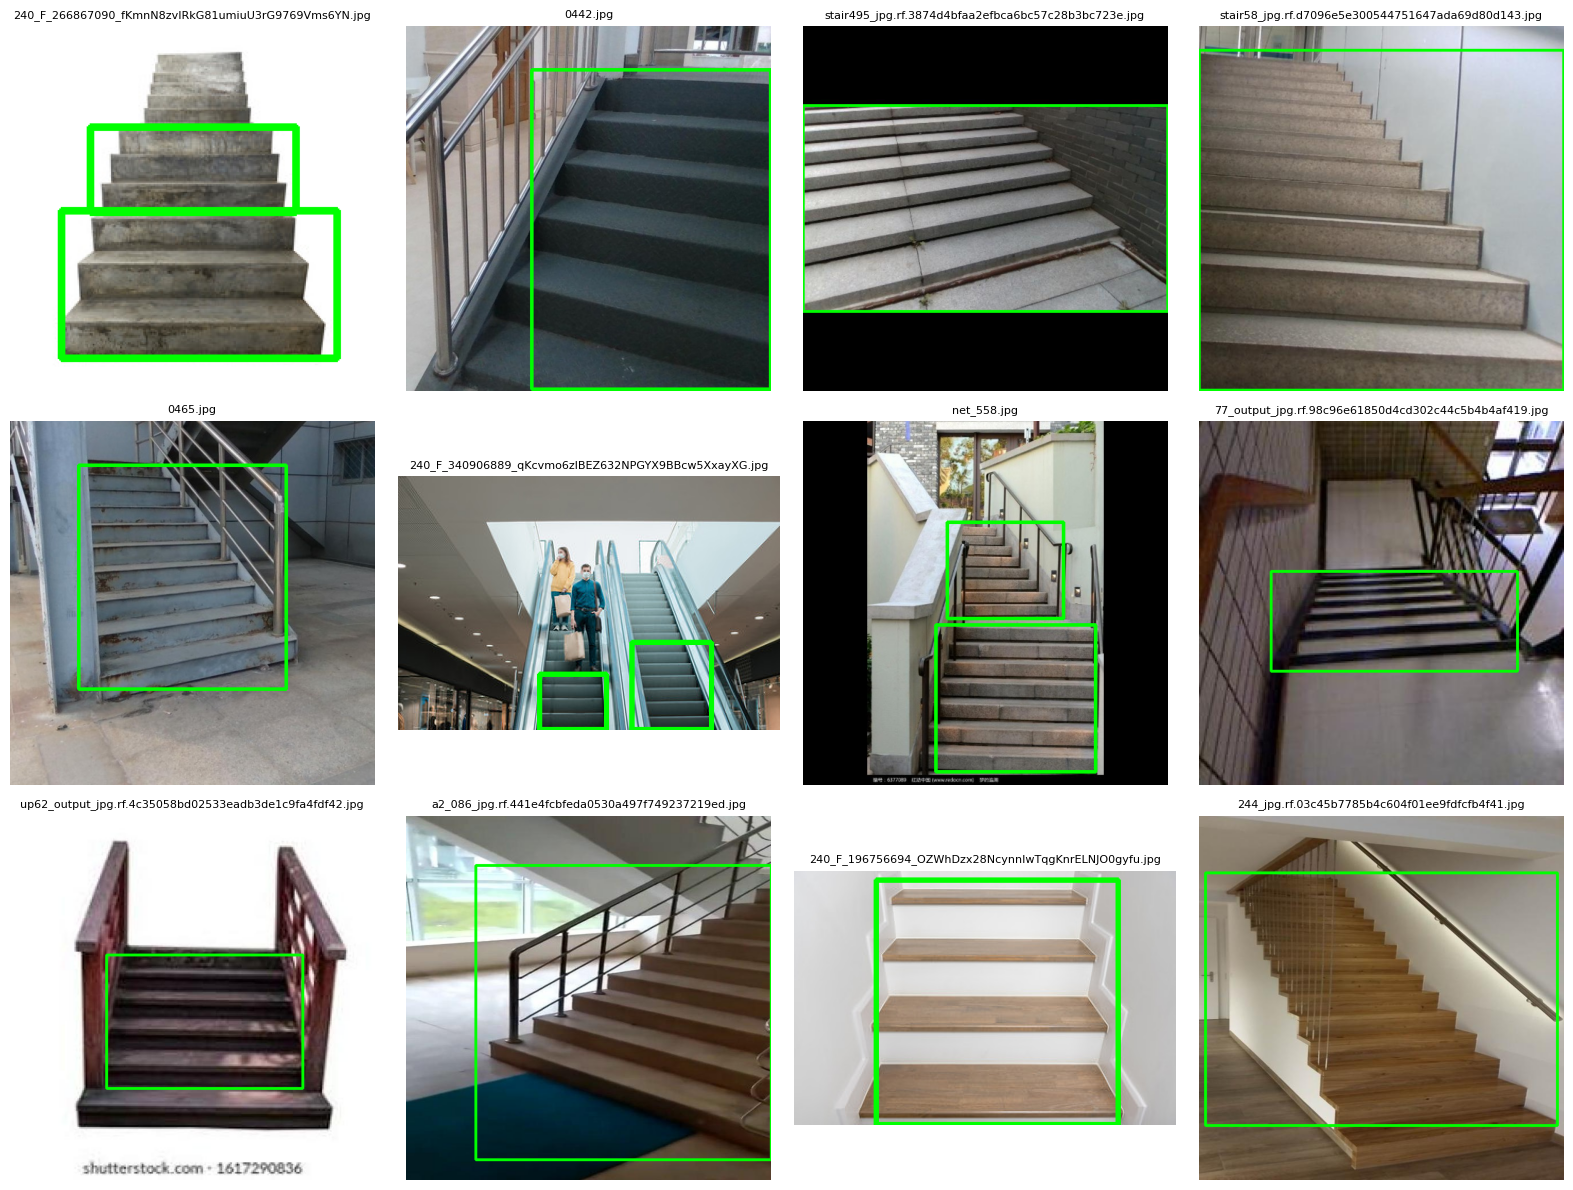

In [17]:
import random, cv2
from pathlib import Path
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/Hazard_Detection/raw_datasets/stairs/kaggle_1/final stairs/YOLO")            # folder with images/ and labels/
imgs = list(ROOT.rglob("*.jpg")) + list(ROOT.rglob("*.png"))
random.seed(51)
sample = random.sample(imgs, min(12, len(imgs)))

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, p in zip(axes.ravel(), sample):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    H, W = im.shape[:2]
    lab = p.parents[1] / "labels" / p.parent.name / (p.stem + ".txt")
    if not lab.exists():
        lab = next(ROOT.rglob(p.stem + ".txt"), None)
    if lab and lab.exists():
        for line in lab.read_text().splitlines():
            c, x, y, w, h = map(float, line.split())
            x1, y1 = int((x - w/2) * W), int((y - h/2) * H)
            x2, y2 = int((x + w/2) * W), int((y + h/2) * H)
            cv2.rectangle(im, (x1, y1), (x2, y2), (0, 255, 0), 3)
    ax.imshow(im); ax.axis("off"); ax.set_title(p.name, fontsize=8)
plt.tight_layout(); plt.show()